# Timing versus Intensity of Breeding-Site Clean-Up Campaigns for Dengue Control in Colombo

*Summary (to be completed when the results are in):* a host–vector dengue model (SEIR humans, SEI *Aedes* mosquitoes), solved with hand-written Euler and RK4 integrators, calibrated to weekly reported cases in Colombo District with a hand-written Metropolis MCMC sampler, and used to compare clean-up campaigns of different intensity and start week.

In [1]:
import os, time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

SEED = 42                                  # global seed, used by every random step in this notebook
rng = np.random.default_rng(SEED)
os.makedirs("figures", exist_ok=True)
print("numpy", np.__version__, "| matplotlib", matplotlib.__version__)

numpy 2.4.6 | matplotlib 3.10.0


## 1. Problem and question

Dengue is endemic in Sri Lanka, and Colombo District is consistently among the most affected districts. Cases rise sharply after the south-west monsoon, as they did again in 2026. The main community response is breeding-site clean-up, which reduces the number of new adult *Aedes* mosquitoes. Health authorities must decide when to start a campaign and how intensive to make it.

**Question:** how early and how large must a breeding-site clean-up campaign be to halve the peak weekly dengue case count in Colombo District?

The answer is reported with posterior uncertainty bands, not single runs.

## 2. Model, assumptions and equations

**State variables.** Humans are tracked as fractions of the effective susceptible population $N$: susceptible $s$, exposed $e$, infectious $i$, recovered $r$, and cumulative incidence $c$. Mosquitoes are tracked per human: susceptible $V_s$, exposed $V_e$, infectious $V_i$.

$$
\begin{aligned}
\frac{ds}{dt} &= -\beta V_i s, &
\frac{dV_s}{dt} &= \lambda(t) - \beta i V_s - \mu_v V_s,\\
\frac{de}{dt} &= \beta V_i s - \sigma_h e, &
\frac{dV_e}{dt} &= \beta i V_s - (\sigma_v + \mu_v) V_e,\\
\frac{di}{dt} &= \sigma_h e - \gamma i, &
\frac{dV_i}{dt} &= \sigma_v V_e - \mu_v V_i,\\
\frac{dr}{dt} &= \gamma i, &
\frac{dc}{dt} &= \sigma_h e .
\end{aligned}
$$

**Clean-up campaign.** A campaign that starts on day $t_c$ cuts mosquito recruitment by a fraction $p$:

$$\lambda(t) = m_0 \mu_v \left(1 - p\,\mathbf{1}[t \ge t_c]\right).$$

**Basic reproduction number** (next-generation matrix, host → vector → host):

$$R_0^2 = \frac{\beta^2 m_0 \sigma_v}{\gamma\, \mu_v (\sigma_v + \mu_v)}, \qquad R_0(p)^2 = R_0^2 (1 - p), \qquad p_c = 1 - \frac{1}{R_0^2}.$$

A campaign applied from the start stops the outbreak exactly when $p > p_c$.

**Observation model** (used from section 5): weekly reported cases $y_w \sim \text{NegBin}\big(\mu_w = \rho N \Delta c_w,\ k\big)$.

| Symbol | Meaning | Units | Value | Source |
|---|---|---|---|---|
| $\sigma_h$ | 1 / human intrinsic incubation period | 1/day | 1/5.5 | [literature, to cite] |
| $\gamma$ | 1 / human infectious period | 1/day | 1/5 | [literature, to cite] |
| $\sigma_v$ | 1 / extrinsic incubation period in the mosquito | 1/day | 1/10 | [literature, to cite] |
| $\mu_v$ | adult *Aedes* death rate (1 / lifespan) | 1/day | 1/14 | [literature, to cite] |
| $m_0$ | baseline adult mosquitoes per human | – | 2 | assumed; varied in sensitivity |
| $N$ | effective susceptible population = susceptible fraction × district population | people | 0.30 × 2,375,415 | Census 2024; fraction assumed |
| $\beta$ | transmission rate (same in both directions) | 1/day | fitted | – |
| $\rho$ | reporting fraction | – | fitted | – |
| $I_0$ | infectious people at $t = 0$ | people | fitted | – |
| $k$ | negative-binomial dispersion | – | 20 | assumed |

**Assumptions**
1. Closed population over one season; births, deaths and migration of humans are ignored.
2. One circulating serotype with lasting immunity within the season.
3. Homogeneous mixing across the district.
4. The same transmission rate $\beta$ applies human → mosquito and mosquito → human.
5. A campaign cuts the recruitment of new adult mosquitoes; adults already alive die off at their natural rate.
6. The susceptible fraction is fixed (it trades off exactly with $\rho$ within one wave) and is varied in the sensitivity analysis.
7. The reporting fraction $\rho$ is constant over the season.

**Concepts used:** population and epidemic models (SEIR / SEI); numerical ODE solvers (Euler, RK4, error orders); MCMC and the Metropolis algorithm; Monte Carlo simulation and input modelling.

## 3. Implementation

All solvers and the model are written from scratch with NumPy. The time step is $\Delta t = 0.5$ day.

In [2]:
N_POP = 2_375_415        # Colombo District population, Census of Population and Housing 2024 (final report)
SUSC_FRAC = 0.30         # ASSUMED share of the population susceptible to the circulating serotype (varied in sensitivity)
N = SUSC_FRAC * N_POP    # effective susceptible population [people]

FIXED = dict(
    sigma_h = 1/5.5,     # 1 / human intrinsic incubation period   [1/day]
    gamma   = 1/5.0,     # 1 / human infectious period             [1/day]
    sigma_v = 1/10.0,    # 1 / extrinsic incubation in the mosquito [1/day]
    mu_v    = 1/14.0,    # 1 / adult Aedes lifespan                [1/day]
    m0      = 2.0,       # baseline adult mosquitoes per human     [-]
)
DT = 0.5                 # RK4 time step [day]
# state vector y = [s, e, i, r, c, Vs, Ve, Vi]
#   s, e, i, r : fractions of N (sum to 1);  c : cumulative incidence (fraction of N)
#   Vs, Ve, Vi : mosquitoes per human

In [3]:
def rhs(t, y, beta, lam, P=FIXED):
    """Host-vector SEIR-SEI derivatives. lam = mosquito recruitment rate [mosquitoes per human per day]."""
    s, e, i, r, c, Vs, Ve, Vi = y
    sh, g, sv, mv = P["sigma_h"], P["gamma"], P["sigma_v"], P["mu_v"]
    inf_h = beta * Vi * s            # new human infections   [1/day]
    inf_v = beta * i * Vs            # new mosquito infections [1/day]
    return np.array([
        -inf_h,
        inf_h - sh * e,
        sh * e - g * i,
        g * i,
        sh * e,                      # cumulative incidence -> weekly cases
        lam - inf_v - mv * Vs,
        inf_v - (sv + mv) * Ve,
        sv * Ve - mv * Vi,
    ])

Both solvers are fixed-step. Explicit Euler has global error $O(\Delta t)$; classical RK4 has global error $O(\Delta t^4)$ for smooth right-hand sides.

In [4]:
def euler(f, y0, t0, t1, dt):
    """Explicit Euler, fixed step. Returns times and states (rows)."""
    n = int(round((t1 - t0) / dt))
    ts = t0 + dt * np.arange(n + 1)
    ys = np.empty((n + 1, len(y0))); ys[0] = y0
    for k in range(n):
        ys[k + 1] = ys[k] + dt * f(ts[k], ys[k])
    return ts, ys

def rk4(f, y0, t0, t1, dt):
    """Classical fourth-order Runge-Kutta, fixed step. Returns times and states (rows)."""
    n = int(round((t1 - t0) / dt))
    ts = t0 + dt * np.arange(n + 1)
    ys = np.empty((n + 1, len(y0))); ys[0] = y0
    for k in range(n):
        t, y = ts[k], ys[k]
        k1 = f(t, y)
        k2 = f(t + dt/2, y + dt/2 * k1)
        k3 = f(t + dt/2, y + dt/2 * k2)
        k4 = f(t + dt, y + dt * k3)
        ys[k + 1] = y + dt/6 * (k1 + 2*k2 + 2*k3 + k4)
    return ts, ys

The campaign makes $\lambda(t)$ jump at $t_c$. If a solver step straddled the jump, RK4 would lose its fourth-order accuracy. `simulate` therefore integrates in two segments that meet exactly at $t_c$, which must lie on the time grid.

In [5]:
def initial_state(I0, m=None, P=FIXED):
    """I0 infectious people at t = 0; mosquitoes start uninfected at density m (default m0)."""
    m = P["m0"] if m is None else m
    i0 = I0 / N
    return np.array([1 - i0, 0.0, i0, 0.0, 0.0, m, 0.0, 0.0])

def simulate(beta, I0, n_weeks, p=0.0, t_c=np.inf, dt=DT, solver=rk4, y0=None, P=FIXED):
    """Run the model for n_weeks. A clean-up campaign cuts mosquito recruitment by fraction p from day t_c.
    Integrated in two segments split exactly at t_c, so no solver step straddles the jump in recruitment."""
    T = 7 * n_weeks
    y0 = initial_state(I0, P=P) if y0 is None else y0
    lam0 = P["m0"] * P["mu_v"]
    t_c = min(max(t_c, 0.0), T)
    assert abs(t_c / dt - round(t_c / dt)) < 1e-9, "t_c must lie on the time grid"
    segs = [(0.0, t_c, lam0), (t_c, T, lam0 * (1 - p))]
    ts_all, ys_all = [np.array([0.0])], [y0[None, :]]
    y = y0
    for a, b, lam in segs:
        if b - a < 1e-12:
            continue
        ts, ys = solver(lambda t, yy: rhs(t, yy, beta, lam, P), y, a, b, dt)
        ts_all.append(ts[1:]); ys_all.append(ys[1:]); y = ys[-1]
    return np.concatenate(ts_all), np.vstack(ys_all)

def weekly_cases(ts, ys, rho):
    """Expected reported cases per week = rho * N * (increase in cumulative incidence over the week)."""
    week_idx = [np.argmin(abs(ts - 7 * w)) for w in range(int(round(ts[-1] / 7)) + 1)]
    c_week = ys[week_idx, 4]
    return rho * N * np.diff(c_week)

def R0(beta, p=0.0, P=FIXED):
    """Basic reproduction number (host -> vector -> host, square root of the two-generation product)."""
    m = P["m0"] * (1 - p)
    return np.sqrt(beta**2 * m * P["sigma_v"] / (P["gamma"] * P["mu_v"] * (P["sigma_v"] + P["mu_v"])))

def p_crit(beta, P=FIXED):
    """Smallest recruitment cut that stops an outbreak: R0(p)^2 = R0^2 (1 - p) = 1."""
    return 1 - 1 / R0(beta, P=P)**2

BETA_TEST, I0_TEST = 0.35, 50
ts, ys = simulate(BETA_TEST, I0_TEST, n_weeks=25)
wk = weekly_cases(ts, ys, rho=0.1)
print(f"R0 = {R0(BETA_TEST):.3f}, p_c = {p_crit(BETA_TEST):.3f}")
print(f"peak weekly cases (rho = 0.1) = {wk.max():.0f} in week {wk.argmax() + 1}")
t0 = time.perf_counter()
for _ in range(20): simulate(BETA_TEST, I0_TEST, n_weeks=25)
print(f"one 25-week RK4 solve: {(time.perf_counter() - t0) / 20 * 1000:.1f} ms")

R0 = 3.163, p_c = 0.900
peak weekly cases (rho = 0.1) = 14071 in week 14
one 25-week RK4 solve: 11.9 ms


## 4. Verification

Each check ends in an `assert`, so a failure stops *Run all*.

**V1. Conservation.** Without a campaign, $s+e+i+r = 1$ and $V_s+V_e+V_i = m_0$ for all time. With a campaign from $t_c$, the mosquito total obeys $\dot V = m_0\mu_v(1-p) - \mu_v V$, so $V(t) = m_0\left[1 - p\left(1 - e^{-\mu_v (t - t_c)}\right)\right]$.

In [6]:
ts, ys = simulate(BETA_TEST, I0_TEST, n_weeks=25)
err_h = np.max(np.abs(ys[:, :4].sum(axis=1) - 1))
err_v = np.max(np.abs(ys[:, 5:].sum(axis=1) - FIXED["m0"]))
print(f"max |s+e+i+r - 1| = {err_h:.2e},  max |Vs+Ve+Vi - m0| = {err_v:.2e}")
assert err_h < 1e-10 and err_v < 1e-10
print("PASS: humans and mosquitoes conserved (no campaign)")

# with a campaign the mosquito total relaxes to m0 (1 - p)
ts, ys = simulate(BETA_TEST, I0_TEST, n_weeks=40, p=0.4, t_c=35.0)
Vtot = ys[:, 5:].sum(axis=1)
expected = FIXED["m0"] * (1 - 0.4 * (1 - np.exp(-FIXED["mu_v"] * np.clip(ts - 35.0, 0, None))))
err = np.max(np.abs(Vtot - expected))
print(f"max |V_total - analytic m0(1 - p(1 - e^(-mu_v (t - t_c))))| = {err:.2e}")
assert err < 1e-8
print("PASS: mosquito total follows the analytic relaxation after the campaign starts")

max |s+e+i+r - 1| = 8.88e-16,  max |Vs+Ve+Vi - m0| = 4.44e-16
PASS: humans and mosquitoes conserved (no campaign)
max |V_total - analytic m0(1 - p(1 - e^(-mu_v (t - t_c))))| = 4.11e-09
PASS: mosquito total follows the analytic relaxation after the campaign starts


**V2. Limiting case.** With $\beta = 0$ there is no transmission: cumulative incidence and infected mosquitoes stay at zero, and infectious humans decay as $i_0 e^{-\gamma t}$. The tolerance allows for RK4's own error on this exponential (about $3 \times 10^{-7}$ relative at $\Delta t = 0.5$).

In [7]:
ts, ys = simulate(0.0, I0_TEST, n_weeks=25)
assert np.max(ys[:, 4]) < 1e-15 and np.max(ys[:, 6:]) < 1e-15
i_exact = (I0_TEST / N) * np.exp(-FIXED["gamma"] * ts)
rel = np.max(np.abs(ys[:, 2] - i_exact)) / (I0_TEST / N)
print(f"max relative error vs i0 exp(-gamma t) = {rel:.1e}")
assert rel < 1e-5
print("PASS: beta = 0 gives no new infections, and i(t) decays as i0 exp(-gamma t)")

max relative error vs i0 exp(-gamma t) = 3.3e-07
PASS: beta = 0 gives no new infections, and i(t) decays as i0 exp(-gamma t)


**V3. Independent $R_0$ check.** $R_0$ is recomputed numerically as the spectral radius of the next-generation matrix $K = F V^{-1}$ for the infected compartments $(e, i, V_e, V_i)$, and compared with the closed form.

In [8]:
def R0_ngm(beta, P=FIXED):
    sh, g, sv, mv, m = P["sigma_h"], P["gamma"], P["sigma_v"], P["mu_v"], P["m0"]
    # infected compartments x = (e, i, Ve, Vi) at the disease-free state (s = 1, Vs = m0)
    F = np.array([[0, 0,      0, beta],
                  [0, 0,      0, 0   ],
                  [0, beta*m, 0, 0   ],
                  [0, 0,      0, 0   ]], dtype=float)
    V = np.array([[ sh, 0, 0,       0 ],
                  [-sh, g, 0,       0 ],
                  [ 0,  0, sv + mv, 0 ],
                  [ 0,  0, -sv,     mv]], dtype=float)
    K = F @ np.linalg.inv(V)
    return np.max(np.abs(np.linalg.eigvals(K)))

for b in [0.1, 0.2, 0.35, 0.5]:
    a, n_ = R0(b), R0_ngm(b)
    print(f"beta = {b:.2f}: closed form R0 = {a:.6f}, next-generation matrix = {n_:.6f}")
    assert abs(a - n_) < 1e-8
print("PASS: closed-form R0 equals the spectral radius of the next-generation matrix")

beta = 0.10: closed form R0 = 0.903696, next-generation matrix = 0.903696
beta = 0.20: closed form R0 = 1.807392, next-generation matrix = 1.807392
beta = 0.35: closed form R0 = 3.162936, next-generation matrix = 3.162936
beta = 0.50: closed form R0 = 4.518481, next-generation matrix = 4.518481
PASS: closed-form R0 equals the spectral radius of the next-generation matrix


**V4. Analytic threshold.** Mosquitoes start at the reduced equilibrium $m_0(1-p)$ and the campaign runs from $t = 0$. Just below $p_c$ the late-time growth rate of infectious humans must be positive; just above $p_c$ it must be negative.

In [9]:
def growth_rate(beta, p, days=600):
    """Late-time exponential growth rate of infectious humans, starting at the reduced mosquito equilibrium."""
    m = FIXED["m0"] * (1 - p)
    y0 = initial_state(1e-3, m=m)            # tiny seed keeps s close to 1 (linear regime)
    ts, ys = simulate(beta, 1e-3, n_weeks=days // 7, p=p, t_c=0.0, y0=y0)
    late = ts > ts[-1] - 100
    return np.polyfit(ts[late], np.log(ys[late, 2]), 1)[0]

pc = p_crit(BETA_TEST)
r_below, r_above = growth_rate(BETA_TEST, pc - 0.03), growth_rate(BETA_TEST, pc + 0.03)
print(f"p_c = {pc:.4f}: growth rate at p_c - 0.03 = {r_below:+.4f}/day, at p_c + 0.03 = {r_above:+.4f}/day")
assert r_below > 0 > r_above
print("PASS: the outbreak grows just below p_c and dies out just above it")

p_c = 0.9000: growth rate at p_c - 0.03 = +0.0090/day, at p_c + 0.03 = -0.0111/day
PASS: the outbreak grows just below p_c and dies out just above it


**V5. Time-step convergence.** Cumulative incidence at week 25 is compared with a reference RK4 solution at $\Delta t = 1/128$ day. The fitted log–log slopes must match the theoretical orders: 1 for Euler and 4 for RK4.

dt      Euler error   RK4 error
1.0     2.079e-04     9.198e-09
0.5     1.069e-04     5.520e-10
0.25    5.413e-05     3.382e-11
0.125   2.723e-05     2.091e-12
0.0625  1.365e-05     1.296e-13
fitted order: Euler 0.98 (expected 1), RK4 4.03 (expected 4)
PASS: measured orders match theory


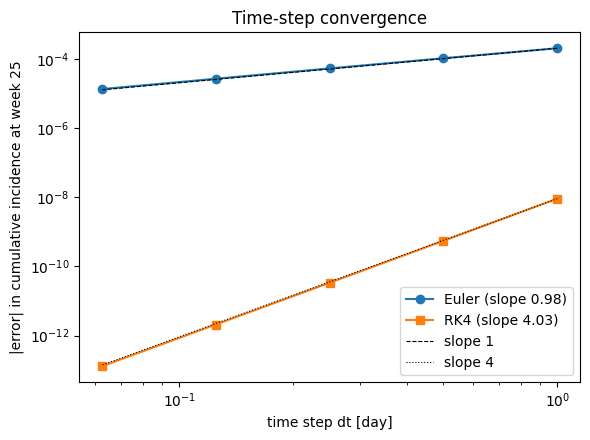

In [10]:
def c_final(solver, dt):
    ts, ys = simulate(BETA_TEST, I0_TEST, n_weeks=25, dt=dt, solver=solver)
    return ys[-1, 4]

ref = c_final(rk4, 1/128)
dts = np.array([1.0, 0.5, 0.25, 0.125, 0.0625])
err_e = np.array([abs(c_final(euler, d) - ref) for d in dts])
err_r = np.array([abs(c_final(rk4, d) - ref) for d in dts])
slope_e = np.polyfit(np.log(dts), np.log(err_e), 1)[0]
slope_r = np.polyfit(np.log(dts), np.log(err_r), 1)[0]
print("dt      Euler error   RK4 error")
for d, a, b in zip(dts, err_e, err_r): print(f"{d:<7} {a:.3e}     {b:.3e}")
print(f"fitted order: Euler {slope_e:.2f} (expected 1), RK4 {slope_r:.2f} (expected 4)")
assert 0.8 < slope_e < 1.2 and 3.5 < slope_r < 4.5
print("PASS: measured orders match theory")

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.loglog(dts, err_e, "o-", label=f"Euler (slope {slope_e:.2f})")
ax.loglog(dts, err_r, "s-", label=f"RK4 (slope {slope_r:.2f})")
ax.loglog(dts, err_e[0] * dts / dts[0], "k--", lw=0.8, label="slope 1")
ax.loglog(dts, err_r[0] * (dts / dts[0])**4, "k:", lw=0.8, label="slope 4")
ax.set_xlabel("time step dt [day]"); ax.set_ylabel("|error| in cumulative incidence at week 25")
ax.set_title("Time-step convergence"); ax.legend(); fig.tight_layout()
fig.savefig("figures/convergence.png", dpi=150)
plt.show()

## 5. Experiments and results

*Calibration (Metropolis MCMC), parameter recovery and campaign scenarios: to be added.*

## 6. Discussion and limitations

*To be added.*

**Web demo reference value:** *to be added.*

## 7. References

*To be added (IEEE style).*